# 01. Dataset Inspection & Data Quality Audit — UCI Online Retail II

**Project:** E-Commerce Customer Analytics  
**Objective:** Perform a thorough, **read-only** audit of the combined UCI Online Retail II CSV file (`2009–2010` and `2010–2011`) to understand its schema, completeness, duplicates, cancellations, returns, adjustments, and anomalies **before** making any cleaning decisions.

> **Audit Rules Followed:**
> - Discover the dataset file dynamically from the workspace (never hardcode filenames).
> - Preserve the original CSV untouched — no records are deleted or modified in this notebook.
> - Distinguish cancelled invoices (`C`-prefixed), inventory write-offs, bad-debt adjustments (`A`-prefixed), and normal sales carefully.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Ensure project root is on sys.path so we can import modular helpers from src/
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils.paths import discover_dataset_csvs
from src.data.audit import build_data_quality_summary, classify_records, load_raw_transactions

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

discovered_csvs = discover_dataset_csvs(PROJECT_ROOT)
print("Discovered dataset CSV(s):")
for p in discovered_csvs:
    size_mb = p.stat().st_size / (1024 * 1024)
    print(f" - {p.relative_to(PROJECT_ROOT)} ({size_mb:.2f} MB)")

DATASET_PATH = discovered_csvs[0]
df, encoding_used = load_raw_transactions(DATASET_PATH)
print(f"\nLoaded '{DATASET_PATH.name}' using encoding='{encoding_used}'.")

Discovered dataset CSV(s):
 - dataset\Ecommerce.csv (90.46 MB)



Loaded 'Ecommerce.csv' using encoding='utf-8'.


### Dataset Discovery & Loading Notes
- Dynamic workspace discovery located **`dataset/Ecommerce.csv`** (~`90.46 MB`) without assuming a filename.
- The file decoded cleanly using **`utf-8`**.
- `Invoice` and `StockCode` were loaded explicitly as `string` types so leading prefixes (`C` for cancellations, `A` for bad-debt adjustments) and mixed alphanumeric product codes (`79323P`, `85123A`) are never coerced or truncated.

In [2]:
print(f"Dataset dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns")
mem_mb = df.memory_usage(deep=True).sum() / (1024 * 1024)
print(f"Approximate memory usage: {mem_mb:.2f} MB")

print("\nColumn names and data types:")
display(df.dtypes.to_frame("dtype"))

print("\nFirst 5 records (head):")
display(df.head(5))

print("\nLast 5 records (tail):")
display(df.tail(5))

Dataset dimensions: 1,067,371 rows x 8 columns
Approximate memory usage: 136.64 MB

Column names and data types:


,dtype
Invoice,string
StockCode,string
Description,str
Quantity,int64
InvoiceDate,str
Price,float64
Customer ID,float64
Country,str



First 5 records (head):


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom



Last 5 records (tail):


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France
1067370,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.00,12680.0,France


### Schema & First/Last Records Analysis
- The combined dataset contains **1,067,371 rows** and **8 columns** (`Invoice`, `StockCode`, `Description`, `Quantity`, `InvoiceDate`, `Price`, `Customer ID`, `Country`), matching the UCI Online Retail II structure.
- The earliest displayed records start on **2009-12-01 07:45:00** (`Invoice 489434`) and the final records end on **2011-12-09 12:50:00** (`Invoice 581587`), confirming both yearly sheets are present.
- `Customer ID` is currently typed as `float64` (e.g., `13085.0`) solely because pandas cannot store `NaN` inside a standard `int64` column. `InvoiceDate` is still a string (`str`) and needs datetime conversion during preprocessing.

,missing_count,missing_pct,non_null_count
Invoice,0,0.0000,1067371
StockCode,0,0.0000,1067371
Description,4382,0.4105,1062989
Quantity,0,0.0000,1067371
InvoiceDate,0,0.0000,1067371
Price,0,0.0000,1067371
Customer ID,243007,22.7669,824364
Country,0,0.0000,1067371


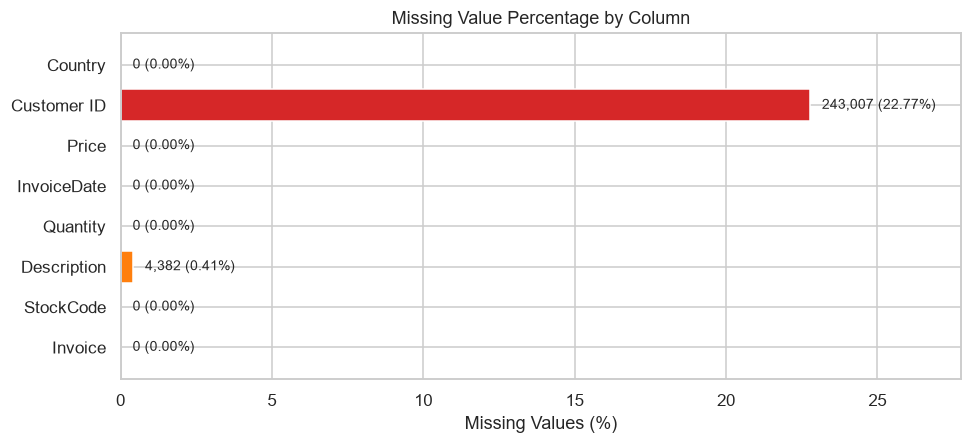

In [3]:
missing_df = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(4),
    "non_null_count": df.notna().sum(),
})
display(missing_df)

fig, ax = plt.subplots(figsize=(9, 4.2))
cols = missing_df.index.tolist()
pcts = missing_df["missing_pct"].values
colors = ["#d62728" if val > 5 else ("#ff7f0e" if val > 0 else "#4c72b0") for val in pcts]
bars = ax.barh(cols, pcts, color=colors)
ax.set_xlabel("Missing Values (%)")
ax.set_title("Missing Value Percentage by Column")
ax.set_xlim(0, max(pcts.max() * 1.22, 5))
for bar, cnt, pct in zip(bars, missing_df["missing_count"], pcts):
    ax.text(bar.get_width() + 0.4, bar.get_y() + bar.get_height() / 2,
            f"{cnt:,} ({pct:.2f}%)", va="center", fontsize=9)
plt.tight_layout()
plt.show()

### Missing Values Analysis
- Only **two columns** contain missing values:
  - **`Customer ID`**: **243,007 missing rows (`22.77%`)** — nearly one in four transaction rows has no registered customer identifier (typical of guest checkouts, POS sales, or internal inventory adjustments).
  - **`Description`**: **4,382 missing rows (`0.41%`)** — product descriptions are blank on a small subset of rows.
- The remaining 6 columns (`Invoice`, `StockCode`, `Quantity`, `InvoiceDate`, `Price`, `Country`) have **zero missing values**.
- Because customer segmentation and RFM/CLV modeling rely on `Customer ID`, missing customer rows cannot be directly assigned to customers—yet keeping them for store-level revenue/product inspection before separating them for customer modeling preserves full analytical context.

Exact duplicate rows (extra copies, keep='first'): 34,335 (3.22%)
Total rows involved in exact duplicates (keep=False): 67,242
Rows in Dec 1-9, 2010 window: 45,046 (duplicates inside window: 22,844)


,duplicate_rows
Before 2010-12-01 (Year 2009-10 only),6544
2010-12-01 to 2010-12-09 (Sheet overlap window),22844
From 2010-12-10 onward (Year 2010-11 only),4947


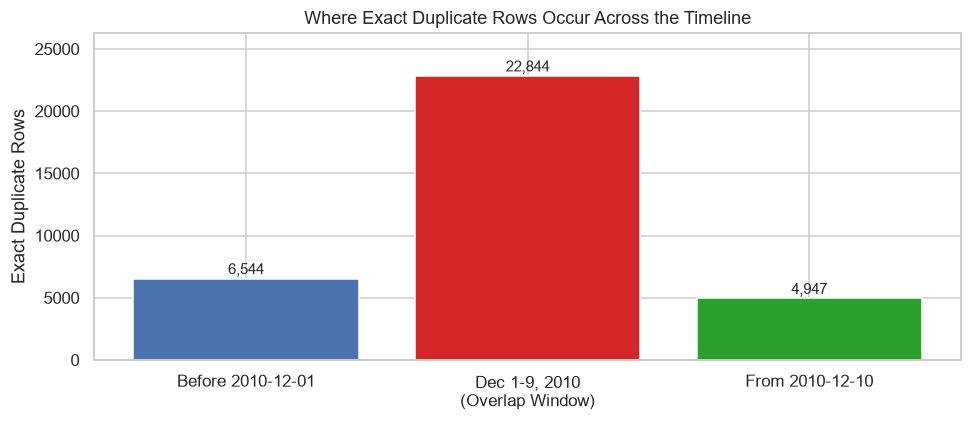

In [4]:
dates = pd.to_datetime(df["InvoiceDate"], errors="coerce")
dup_first = df.duplicated(keep="first")
dup_all = df.duplicated(keep=False)

overlap_mask = (dates >= "2010-12-01") & (dates < "2010-12-10")
period_dups = pd.Series({
    "Before 2010-12-01 (Year 2009-10 only)": int(dup_first[dates < "2010-12-01"].sum()),
    "2010-12-01 to 2010-12-09 (Sheet overlap window)": int(dup_first[overlap_mask].sum()),
    "From 2010-12-10 onward (Year 2010-11 only)": int(dup_first[dates >= "2010-12-10"].sum()),
})

print(f"Exact duplicate rows (extra copies, keep='first'): {int(dup_first.sum()):,} ({dup_first.mean()*100:.2f}%)")
print(f"Total rows involved in exact duplicates (keep=False): {int(dup_all.sum()):,}")
print(f"Rows in Dec 1-9, 2010 window: {int(overlap_mask.sum()):,} (duplicates inside window: {period_dups.iloc[1]:,})")
display(period_dups.to_frame("duplicate_rows"))

fig, ax = plt.subplots(figsize=(9, 4))
palette = ["#4c72b0", "#d62728", "#2ca02c"]
bars = ax.bar(range(len(period_dups)), period_dups.values, color=palette)
ax.set_xticks(range(len(period_dups)))
ax.set_xticklabels(["Before 2010-12-01", "Dec 1-9, 2010\n(Overlap Window)", "From 2010-12-10"])
ax.set_ylabel("Exact Duplicate Rows")
ax.set_title("Where Exact Duplicate Rows Occur Across the Timeline")
for bar, val in zip(bars, period_dups.values):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 350, f"{val:,}", ha="center", fontsize=10)
ax.set_ylim(0, period_dups.max() * 1.15)
plt.tight_layout()
plt.show()

### Duplicate Records Analysis
- There are **34,335 exact duplicate rows (`3.22%`)** across the dataset (involving **67,242 total rows** when counting both originals and copies).
- A critical domain discovery explains **two-thirds (`66.5%`)** of these duplicates: **22,844 duplicate rows** occur specifically between **2010-12-01 and 2010-12-09**. In the original UCI Online Retail II Excel workbook, the `Year 2009-2010` sheet and `Year 2010-2011` sheet overlap across those 9 days, so stacking both sheets directly into one CSV duplicated that overlap window.
- The remaining **11,491 duplicates** (`6,544` before Dec 2010 + `4,947` from Dec 10, 2010 onward) reflect identical line items logged multiple times on the same invoice and timestamp.

,Entity,Unique Count
0,Unique Invoices (all),53628
1,- Standard numeric invoices,45330
2,- Cancelled invoices ('C' prefix),8292
3,- Bad debt adjustment invoices ('A' prefix),6
4,Unique Customer IDs (non-null),5942
5,Unique StockCodes (raw),5305
6,Unique StockCodes (stripped + uppercase),5131
7,Unique Descriptions (stripped),5655
8,Unique Countries,43


Unspecified country rows: 756
Customer IDs with non-integer fractional values: 0


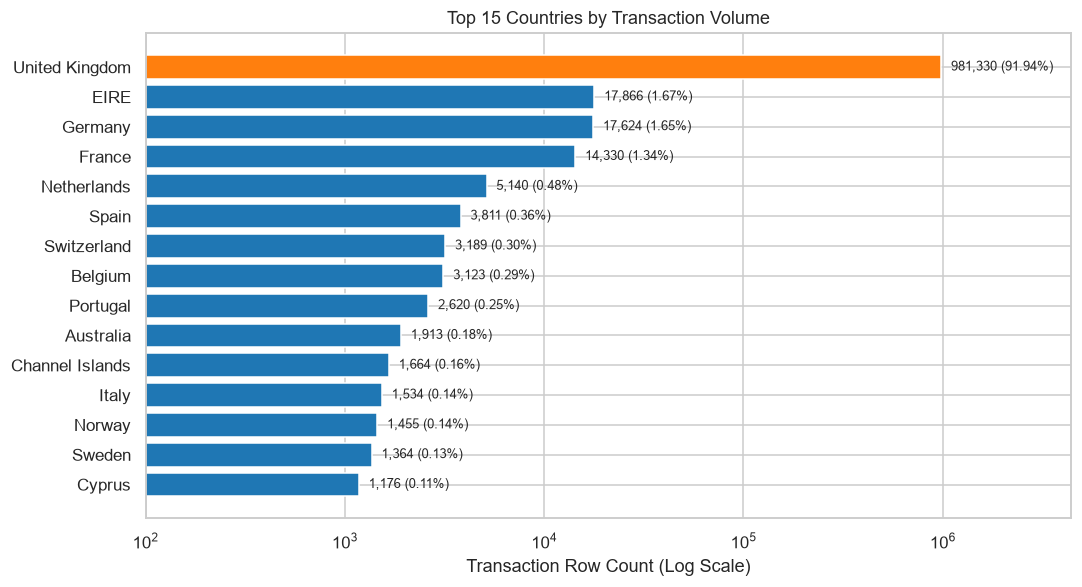

In [5]:
masks = classify_records(df)
inv_clean = masks["invoice_clean"]
stock_clean = masks["stock_clean"]

entity_summary = pd.DataFrame([
    ("Unique Invoices (all)", inv_clean.nunique()),
    ("  - Standard numeric invoices", inv_clean[masks["is_digit_invoice"]].nunique()),
    ("  - Cancelled invoices ('C' prefix)", inv_clean[masks["is_c_invoice"]].nunique()),
    ("  - Bad debt adjustment invoices ('A' prefix)", inv_clean[masks["is_a_invoice"]].nunique()),
    ("Unique Customer IDs (non-null)", df["Customer ID"].nunique(dropna=True)),
    ("Unique StockCodes (raw)", df["StockCode"].nunique(dropna=True)),
    ("Unique StockCodes (stripped + uppercase)", stock_clean.str.upper().nunique()),
    ("Unique Descriptions (stripped)", df["Description"].dropna().astype(str).str.strip().nunique()),
    ("Unique Countries", df["Country"].nunique(dropna=True)),
], columns=["Entity", "Unique Count"])
display(entity_summary)

country_counts = df["Country"].value_counts(dropna=False)
print(f"Unspecified country rows: {int(masks['is_unspecified_country'].sum()):,}")
print(f"Customer IDs with non-integer fractional values: {int((df['Customer ID'].dropna() % 1 != 0).sum())}")

top_countries = country_counts.head(15).sort_values()
fig, ax = plt.subplots(figsize=(10, 5.5))
bar_colors = ["#1f77b4" if c != "United Kingdom" else "#ff7f0e" for c in top_countries.index]
bars = ax.barh(top_countries.index, top_countries.values, color=bar_colors)
ax.set_xscale("log")
ax.set_xlabel("Transaction Row Count (Log Scale)")
ax.set_title("Top 15 Countries by Transaction Volume")
for bar, val in zip(bars, top_countries.values):
    pct = val / len(df) * 100
    ax.text(val * 1.12, bar.get_y() + bar.get_height() / 2, f"{val:,} ({pct:.2f}%)", va="center", fontsize=8.5)
ax.set_xlim(100, top_countries.max() * 4.5)
plt.tight_layout()
plt.show()

### Unique Entity & Country Distribution Analysis
- **Invoices:** **53,628 unique invoices** partition cleanly into **45,330 standard numeric invoices**, **8,292 `C`-prefixed cancellations**, and **6 `A`-prefixed bad-debt adjustments**.
- **Customers:** **5,942 distinct non-null `Customer ID`s**, with zero fractional decimal anomalies (they are clean integer IDs stored as floats due to `NaN`s).
- **Products:** **5,305 raw unique `StockCode`s** collapse to **5,131** when trimmed and uppercased (`174` case/whitespace discrepancies like `m` vs `M` or `85123a` vs `85123A`). Descriptions total **5,655** stripped strings because products occasionally received renamed descriptions or warehouse notes.
- **Geography:** **43 distinct countries**, heavily concentrated in the **United Kingdom (`981,330` rows / `91.94%`)**, followed by EIRE (`17,866`), Germany (`17,624`), and France (`14,330`). Notably, **`756` rows are labeled `Unspecified`**.

Unparseable InvoiceDate values: 0
Date range: 2009-12-01 07:45:00  -->  2011-12-09 12:50:00


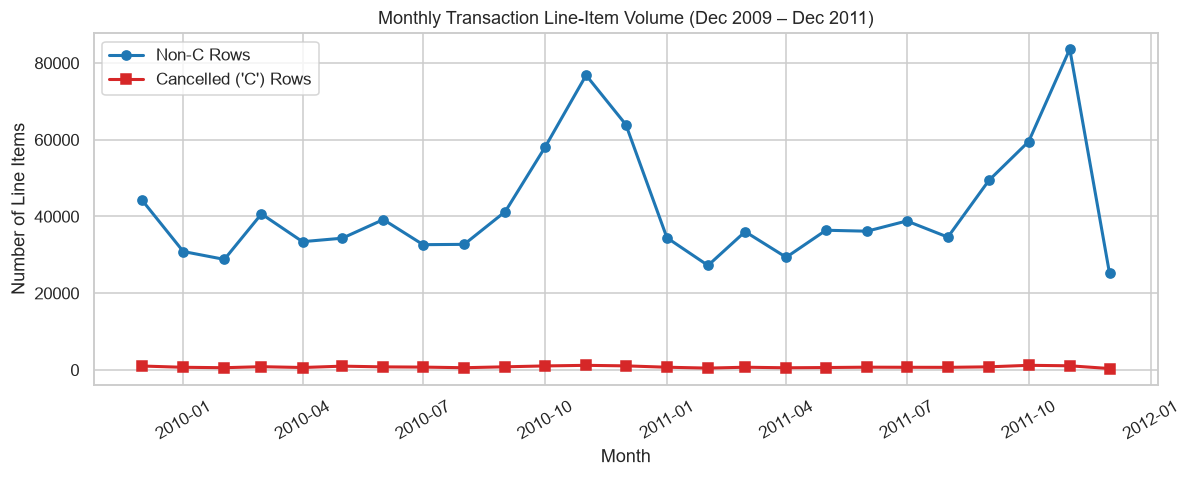

In [6]:
unparseable_dates = int(dates.isna().sum())
print(f"Unparseable InvoiceDate values: {unparseable_dates}")
print(f"Date range: {dates.min()}  -->  {dates.max()}")

monthly_df = pd.DataFrame({
    "Total Rows": dates.dt.to_period("M").value_counts().sort_index(),
    "Normal / Non-C Rows": dates[~masks["is_c_invoice"]].dt.to_period("M").value_counts().sort_index(),
    "Cancelled ('C') Rows": dates[masks["is_c_invoice"]].dt.to_period("M").value_counts().sort_index(),
}).fillna(0).astype(int)
monthly_df.index = monthly_df.index.to_timestamp()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly_df.index, monthly_df["Normal / Non-C Rows"], marker="o", linewidth=2, color="#1f77b4", label="Non-C Rows")
ax.plot(monthly_df.index, monthly_df["Cancelled ('C') Rows"], marker="s", linewidth=2, color="#d62728", label="Cancelled ('C') Rows")
ax.set_title("Monthly Transaction Line-Item Volume (Dec 2009 – Dec 2011)")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Line Items")
ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Date Range & Temporal Coverage Analysis
- **100% of `InvoiceDate` strings parse cleanly** (`0` unparseable timestamps) from **`2009-12-01 07:45:00` to `2011-12-09 12:50:00`** (~24 months + 9 days).
- Notice the sharp Q4 seasonal surges in **October–November 2010** (`59,098` and `78,015` rows) and **October–November 2011** (`60,742` and `84,711` rows), plus the inflated **December 2010** spike (`65,004` rows) driven partially by the Dec 1–9 sheet overlap.
- December 2011 appears lower (`25,526` rows) simply because data collection stops mid-month on **December 9, 2011**.

Quantity summary statistics:


,Quantity
count,1.067371e+06
mean,9.938898e+00
std,1.727058e+02
min,-8.099500e+04
1%,-3.000000e+00
5%,1.000000e+00
25%,1.000000e+00
50%,3.000000e+00
75%,1.000000e+01
95%,3.000000e+01



Price summary statistics:


,Price
count,1.067371e+06
mean,4.649388e+00
std,1.235531e+02
min,-5.359436e+04
1%,2.100000e-01
5%,4.200000e-01
25%,1.250000e+00
50%,2.100000e+00
75%,4.150000e+00
95%,9.950000e+00


,Negative (< 0),Zero (== 0),Positive (> 0)
Quantity,22950,0,1044421
Price,5,6202,1061164


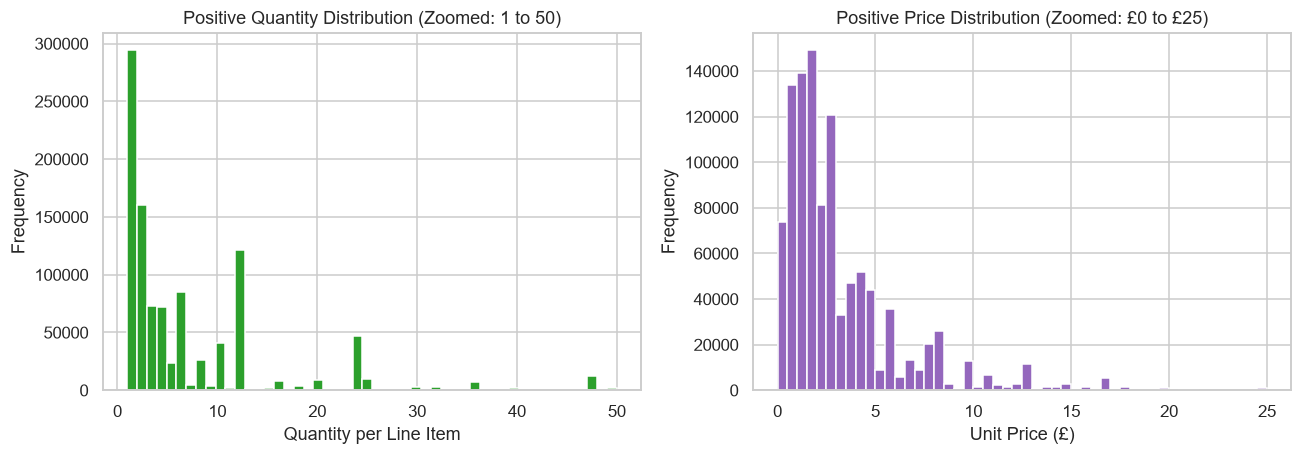

In [7]:
qty = df["Quantity"]
price = df["Price"]

print("Quantity summary statistics:")
display(qty.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame("Quantity"))

print("\nPrice summary statistics:")
display(price.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame("Price"))

sign_breakdown = pd.DataFrame({
    "Negative (< 0)": [int((qty < 0).sum()), int((price < 0).sum())],
    "Zero (== 0)": [int((qty == 0).sum()), int((price == 0).sum())],
    "Positive (> 0)": [int((qty > 0).sum()), int((price > 0).sum())],
}, index=["Quantity", "Price"])
display(sign_breakdown)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
pos_qty_typical = qty[(qty > 0) & (qty <= 50)]
axes[0].hist(pos_qty_typical, bins=50, color="#2ca02c", edgecolor="white")
axes[0].set_title("Positive Quantity Distribution (Zoomed: 1 to 50)")
axes[0].set_xlabel("Quantity per Line Item")
axes[0].set_ylabel("Frequency")

pos_price_typical = price[(price > 0) & (price <= 25)]
axes[1].hist(pos_price_typical, bins=50, color="#9467bd", edgecolor="white")
axes[1].set_title("Positive Price Distribution (Zoomed: £0 to £25)")
axes[1].set_xlabel("Unit Price (£)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### Quantity & Price Distribution Analysis
- **Extreme right-skew and outliers:** While `95%` of line items have `Quantity <= 30` (median `3`) and `Price <= £9.95` (median `£2.10`), extreme values stretch from **`-80,995` to `+80,995`** for `Quantity` and **`-£53,594.36` to `+£38,970.00`** for `Price`.
- **Negative & Zero Quantity:** There are **22,950 negative-quantity rows (`2.15%`)** and **0 zero-quantity rows**.
- **Negative & Zero Price:** There are **5 negative-price rows** and **6,202 zero-price rows (`0.58%`)**.

In [8]:
c_inv = masks["is_c_invoice"]
a_inv = masks["is_a_invoice"]

qty_inv_crosstab = pd.DataFrame([
    ("C-prefixed invoice & Quantity < 0 (Customer Cancellations/Returns)", int(((qty < 0) & c_inv).sum())),
    ("C-prefixed invoice & Quantity > 0 (Anomalous positive C-invoice)", int(((qty > 0) & c_inv).sum())),
    ("Non-C invoice & Quantity < 0 (Warehouse write-offs/adjustments)", int(masks["is_non_c_negative_qty"].sum())),
    ("Non-C invoice & Price == 0 & Quantity > 0 (Free/unpriced items)", int(((price == 0) & (qty > 0)).sum())),
    ("A-prefixed invoice & Price < 0 (Negative bad debt adjustments)", int((a_inv & (price < 0)).sum())),
    ("A-prefixed invoice & Price > 0 (Positive bad debt adjustment)", int((a_inv & (price > 0)).sum())),
], columns=["Record Type", "Row Count"])
display(qty_inv_crosstab)

print("1) Sample C-prefixed cancellation rows:")
display(df[c_inv].head(5))

print("2) Anomalous C-invoice with Quantity > 0:")
display(df[(qty > 0) & c_inv])

print("3) All A-prefixed invoices (Adjust bad debt):")
display(df[a_inv])

print("4) Sample non-C negative quantity rows (warehouse adjustments):")
display(df[masks["is_non_c_negative_qty"]].head(6))

print("5) Sample zero-price positive-quantity rows:")
display(df[(price == 0) & (qty > 0)].head(6))

print("6) Extreme Quantity rows (|Quantity| >= 70,000):")
display(df[qty.abs() >= 70000])

,Record Type,Row Count
0,C-prefixed invoice & Quantity < 0 (Customer Ca...,19493
1,C-prefixed invoice & Quantity > 0 (Anomalous p...,1
2,Non-C invoice & Quantity < 0 (Warehouse write-...,3457
3,Non-C invoice & Price == 0 & Quantity > 0 (Fre...,2745
4,A-prefixed invoice & Price < 0 (Negative bad d...,5
5,A-prefixed invoice & Price > 0 (Positive bad d...,1


1) Sample C-prefixed cancellation rows:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia


2) Anomalous C-invoice with Quantity > 0:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
76799,C496350,M,Manual,1,2010-02-01 08:24:00,373.57,NaN,United Kingdom


3) All A-prefixed invoices (Adjust bad debt):


... (3 outputs left out)

5) Sample zero-price positive-quantity rows:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4674,489825,22076,6 RIBBONS EMPIRE,12,2009-12-02 13:34:00,0.0,16126.0,United Kingdom
5904,489861,DOT,DOTCOM POSTAGE,1,2009-12-02 14:50:00,0.0,NaN,United Kingdom
6378,489882,35751C,NaN,12,2009-12-02 16:22:00,0.0,NaN,United Kingdom
6555,489898,79323G,NaN,954,2009-12-03 09:40:00,0.0,NaN,United Kingdom


6) Extreme Quantity rows (|Quantity| >= 70,000):


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom


### Cancellations, Returns, Adjustments & Extreme Reversals Analysis
Inspecting invoice prefixes alongside `Quantity` and `Price` prevents misclassifying internal accounting entries as customer behavior:
1. **Customer Cancellations (`C`-prefixed invoices):** Account for **19,494 rows** across **8,292 unique invoices** (`19,493` have `Quantity < 0`, plus `1` anomalous manual row `C496350` with `Quantity = +1`, `Price = £373.57`).
2. **Inventory Write-Offs (`Quantity < 0` WITHOUT `C`-prefix):** All **3,457 rows** have **`Price == 0.0`** and **missing `Customer ID`**, with warehouse descriptions like `lost`, `damages`, `short`, `85123a mixed`, or blank descriptions. These are **stock adjustments**, not customer returns.
3. **Bad Debt Adjustments (`A`-prefixed invoices):** **6 rows** (`A506401`–`A563187`, `StockCode='B'`, `Customer ID=NaN`), including all **5 negative-price rows** (`-£53,594.36` to `-£11,062.06`) and one positive offset (`+£11,062.06`).
4. **Massive Order + Immediate Cancellation Pairs:** The two largest quantities in the entire dataset (`±74,215` in `541431`/`C541433` and `±80,995` in `581483`/`C581484`) are giant orders immediately cancelled 12–16 minutes later. Without handling cancellations carefully, gross sales would look inflated by hundreds of thousands of pounds!

,Total Rows,Missing Customer ID,With Customer ID,Missing %
Numeric Invoices (All),1047871,242251,805620,23.12
C-Invoices (Cancellations),19494,750,18744,3.85
A-Invoices (Bad Debt),6,6,0,100.00
Non-C Negative Qty,3457,3457,0,100.00
Zero Price (Price == 0),6202,6131,71,98.86


Non-standard StockCode rows (not 5 digits + optional letters): 6,093 across 62 unique codes
TEST* StockCode rows: 17
Lowercase/note Description rows: 823


,row_count
StockCode,
POST,2122
DOT,1446
M,1421
C2,282
D,177
S,104
BANK CHARGES,102
ADJUST,67
AMAZONFEE,43


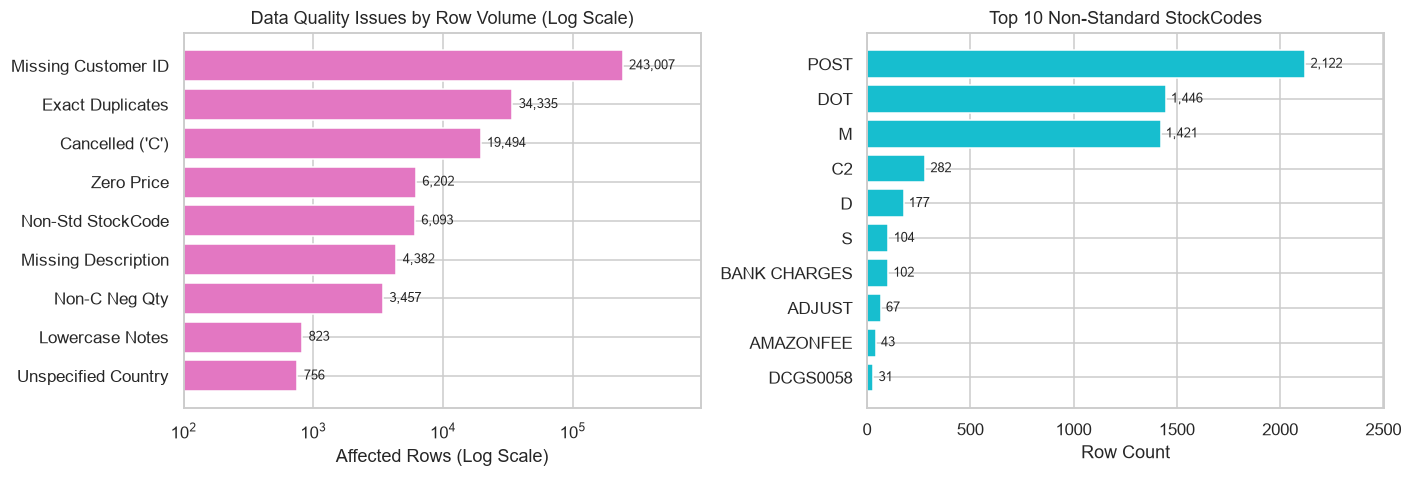

In [9]:
cust_overlap = pd.DataFrame({
    "Total Rows": [
        int(masks["is_digit_invoice"].sum()),
        int(c_inv.sum()),
        int(a_inv.sum()),
        int(masks["is_non_c_negative_qty"].sum()),
        int(masks["is_zero_price"].sum()),
    ],
    "Missing Customer ID": [
        int((masks["is_digit_invoice"] & masks["is_missing_customer"]).sum()),
        int((c_inv & masks["is_missing_customer"]).sum()),
        int((a_inv & masks["is_missing_customer"]).sum()),
        int((masks["is_non_c_negative_qty"] & masks["is_missing_customer"]).sum()),
        int((masks["is_zero_price"] & masks["is_missing_customer"]).sum()),
    ],
}, index=[
    "Numeric Invoices (All)",
    "C-Invoices (Cancellations)",
    "A-Invoices (Bad Debt)",
    "Non-C Negative Qty",
    "Zero Price (Price == 0)",
])
cust_overlap["With Customer ID"] = cust_overlap["Total Rows"] - cust_overlap["Missing Customer ID"]
cust_overlap["Missing %"] = (cust_overlap["Missing Customer ID"] / cust_overlap["Total Rows"] * 100).round(2)
display(cust_overlap)

non_std_counts = masks["stock_clean"][masks["is_non_standard_stock"]].value_counts().head(15)
print(f"Non-standard StockCode rows (not 5 digits + optional letters): {int(masks['is_non_standard_stock'].sum()):,} across {masks['stock_clean'][masks['is_non_standard_stock']].nunique()} unique codes")
print(f"TEST* StockCode rows: {int(masks['is_test_stock'].sum()):,}")
print(f"Lowercase/note Description rows: {int(masks['is_lowercase_desc'].sum()):,}")
display(non_std_counts.to_frame("row_count"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
anomaly_series = pd.Series({
    "Missing Customer ID": int(masks["is_missing_customer"].sum()),
    "Exact Duplicates": int(df.duplicated().sum()),
    "Cancelled ('C')": int(c_inv.sum()),
    "Zero Price": int(masks["is_zero_price"].sum()),
    "Non-Std StockCode": int(masks["is_non_standard_stock"].sum()),
    "Missing Description": int(masks["is_missing_description"].sum()),
    "Non-C Neg Qty": int(masks["is_non_c_negative_qty"].sum()),
    "Lowercase Notes": int(masks["is_lowercase_desc"].sum()),
    "Unspecified Country": int(masks["is_unspecified_country"].sum()),
}).sort_values()
axes[0].barh(anomaly_series.index, anomaly_series.values, color="#e377c2")
axes[0].set_xscale("log")
axes[0].set_title("Data Quality Issues by Row Volume (Log Scale)")
axes[0].set_xlabel("Affected Rows (Log Scale)")
for i, val in enumerate(anomaly_series.values):
    axes[0].text(val * 1.12, i, f"{val:,}", va="center", fontsize=8.5)
axes[0].set_xlim(100, anomaly_series.max() * 4.0)

non_std_plot = non_std_counts.head(10).sort_values()
axes[1].barh(non_std_plot.index, non_std_plot.values, color="#17becf")
axes[1].set_title("Top 10 Non-Standard StockCodes")
axes[1].set_xlabel("Row Count")
for i, val in enumerate(non_std_plot.values):
    axes[1].text(val + 25, i, f"{val:,}", va="center", fontsize=8.5)
axes[1].set_xlim(0, non_std_plot.max() * 1.18)

plt.tight_layout()
plt.show()

### Missing Customer ID Overlap & Non-Standard Codes Analysis
- **Customer ID gaps concentrate in unattributed/internal rows:** Only `3.85%` (`750` of `19,494`) of `C`-prefixed cancellations lack `Customer ID`, whereas **`100%` (`3,457` of `3,457`) of non-`C` negative-quantity write-offs**, **`100%` (`6` of `6`) of `A`-invoices**, and **`98.86%` (`6,131` of `6,202`) of zero-price rows** lack `Customer ID` (leaving only `71` zero-price positive-quantity rows attached to a customer).
- **Non-standard StockCodes (`6,093` rows across `62` codes):** Include shipping/fee/admin entries rather than physical retail products—specifically `POST` (`2,122`), `DOT` (`1,446`), `M`/`m` (`1,426` manual adjustments including `£38,970` on `C556445`), `C2` (`282` carriage), `D` (`177` discounts), `S` (`104` samples), `BANK CHARGES` (`102`), `ADJUST` (`67`), `AMAZONFEE` (`43`), `CRUK` (`16` charity commission), `B` (`6` bad debt), gift vouchers (`gift_0001_*`), and **`17` internal `TEST001`/`TEST002` test product rows**.
- **Operational text in `Description`:** `823` rows contain lowercase warehouse status notes (`check`, `?`, `damages`, `damaged`, `found`, `missing`, `smashed`, `thrown away`) rather than retail product names.

In [10]:
report_df, summary = build_data_quality_summary(df)
reports_dir = PROJECT_ROOT / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

csv_report_path = reports_dir / "data_quality_report.csv"
md_report_path = reports_dir / "data_quality_report.md"

report_df.to_csv(csv_report_path, index=False, encoding="utf-8")

md_lines = [
    "# Data Quality Audit Report — UCI Online Retail II",
    "",
    f"- **Source Dataset:** `{DATASET_PATH.relative_to(PROJECT_ROOT)}` (`{DATASET_PATH.stat().st_size / (1024 * 1024):.2f} MB`, encoding `{encoding_used}`)",
    f"- **Audit Status:** Read-only inspection complete (**no records modified or deleted**)",
    "",
    "## Executive Summary Table",
    "",
    "| Metric | Category | Value | % of Total Rows | Notes |",
    "|---|---|---:|---:|---|",
]
for _, row in report_df.iterrows():
    val_str = f"{row['value']:,}" if isinstance(row["value"], (int, float)) else str(row["value"])
    pct_str = f"{row['percentage_of_rows']}%" if row["percentage_of_rows"] != "" else "—"
    md_lines.append(f"| {row['metric']} | {row['category']} | {val_str} | {pct_str} | {row['notes']} |")

md_lines.extend([
    "",
    "## Key Audit Findings",
    "",
    f"1. **Dataset Scale & Date Coverage:** `{summary['total_rows']:,}` rows x `{summary['total_columns']}` columns spanning `{summary['date_min']}` to `{summary['date_max']}` (`0` unparseable timestamps).",
    f"2. **Missing Values:** `Customer ID` is missing on `{summary['missing_customer_id']:,}` rows (`{summary['missing_customer_id']/summary['total_rows']*100:.2f}%`), and `Description` is missing on `{summary['missing_description']:,}` rows (`{summary['missing_description']/summary['total_rows']*100:.2f}%`, `{summary['missing_desc_no_cust']:,}` of which also lack `Customer ID`).",
    f"3. **Duplicates & Sheet Overlap:** `{summary['exact_duplicates']:,}` exact duplicate rows (`{summary['exact_duplicates']/summary['total_rows']*100:.2f}%`), of which `{summary['overlap_duplicates']:,}` (`{summary['overlap_duplicates']/summary['exact_duplicates']*100:.1f}%` of duplicates) occur in the `2010-12-01` to `2010-12-09` overlap window between the two combined UCI sheets.",
    f"4. **Cancellations vs. Stock Adjustments vs. Bad Debt:** `{summary['cancelled_rows']:,}` rows (`{summary['cancelled_unique_invoices']:,}` `C`-invoices) are cancellations (`{summary['c_pos_qty_rows']}` anomalous row with `Quantity > 0`), `{summary['non_c_neg_qty_rows']:,}` rows are non-`C` negative-quantity warehouse write-offs (all `{summary['non_c_neg_qty_zero_price']:,}` with `Price == 0` and `{summary['non_c_neg_qty_no_cust']:,}` missing `Customer ID`), and `{summary['bad_debt_rows']}` rows are `A`-prefixed bad-debt adjustments (containing all `{summary['neg_price_rows']}` negative-price rows).",
    f"5. **Invalid / Non-Product Entries:** `{summary['zero_price_rows']:,}` rows have `Price == 0`, `{summary['non_std_stock_rows']:,}` rows have non-standard `StockCode`s (postage `POST`/`DOT`, manual `M`/`m`, discounts `D`, bank charges, `TEST001`/`TEST002` across `{summary['test_stock_rows']}` rows), `{summary['lowercase_desc_rows']:,}` rows have lowercase warehouse notes, and `{summary['unspecified_country_rows']:,}` rows have `Country == 'Unspecified'`.",
    "",
    "## Recommended Cleaning Strategy (Awaiting User Approval)",
    "",
    "1. **Keep Raw File Immutable:** Never overwrite `dataset/Ecommerce.csv`; save cleaned outputs into separate derived files (e.g., `dataset/cleaned_transactions.parquet` or `.csv`).",
    f"2. **Remove Exact Duplicates First:** Drop exact duplicate rows (`{summary['exact_duplicates']:,}` rows), which eliminates the `{summary['overlap_duplicates']:,}` Dec 1–9, 2010 sheet-overlap duplicates plus `{summary['exact_duplicates'] - summary['overlap_duplicates']:,}` intra-period duplicates.",
    "3. **Separate Cancellations & Returns (`C`-Invoices) Instead of Blindly Discarding:** Keep a dedicated cancellation flag or return summary so net customer spend / net units properly subtract cancelled orders (including massive paired reversals like `±80,995` and `±74,215`) rather than overstating gross revenue.",
    f"4. **Exclude Non-Customer Operational Noise:** Remove `A`-prefixed bad-debt rows (`{summary['bad_debt_rows']}` rows), non-`C` negative-quantity warehouse write-offs (`{summary['non_c_neg_qty_rows']:,}` rows), `TEST*` rows (`{summary['test_stock_rows']}` rows), and `Price <= 0` records (`{summary['neg_price_rows'] + summary['zero_price_rows']:,}` rows) from revenue/modeling tables.",
    "5. **Handle Non-Standard Service/Fee `StockCode`s Deliberately:** Exclude fees/admin codes (`POST`, `DOT`, `M`/`m`, `BANK CHARGES`, `C2`, `D`, `ADJUST`, `AMAZONFEE`, `CRUK`, `B`) from product-level analytics and RFM product counts (or track postage separately when reconciling invoice totals).",
    f"6. **Normalize Identifiers & Text:** Convert `InvoiceDate` to `datetime`, strip whitespace and normalize `StockCode` casing (`{summary['unique_stockcodes_raw']:,} -> {summary['unique_stockcodes_upper']:,}`), strip `Description`, and standardize non-null `Customer ID` formatting.",
    f"7. **Split Scope for Missing `Customer ID`s:** Retain valid sales without `Customer ID` (`{summary['missing_customer_id']:,}` total rows missing ID) only for aggregate store/product revenue views if needed, and filter strictly to non-null `Customer ID` for customer-level RFM segmentation, churn, and CLV modeling.",
])

md_report_path.write_text("\n".join(md_lines) + "\n", encoding="utf-8")

print(f"Saved CSV report: {csv_report_path.relative_to(PROJECT_ROOT)}")
print(f"Saved Markdown report: {md_report_path.relative_to(PROJECT_ROOT)}")
display(report_df)

Saved CSV report: reports\data_quality_report.csv
Saved Markdown report: reports\data_quality_report.md


,metric,category,value,percentage_of_rows,notes
0,Total rows,Dataset Dimensions,1067371,100.0,Combined 2009-2010 and 2010-2011 transactions
1,Total columns,Dataset Dimensions,8,,"Expected schema: Invoice, StockCode, Descripti..."
2,Missing values (total cells),Missing Values,247389,2.8972,Sum of null cells across all columns
3,Missing Customer ID records,Missing Values,243007,22.7669,Guest/unregistered checkouts or internal stock...
4,Missing Description records,Missing Values,4382,0.4105,"Rows with null product description (4,382 also..."
5,Duplicate records (exact rows),Duplicates,34335,3.2168,"Includes 22,844 duplicates in Dec 1-9, 2010 sh..."
6,Invalid or unusual records (union),Invalid / Unusual Values,12963,1.2145,"Rows with price<=0, non-C qty<0, A-invoices, n..."
7,Cancelled invoice records (C-prefix),Cancellations,19494,1.8264,"Across 8,292 unique C-prefixed invoices (1 has..."
8,Negative quantity records (all),Quantity Anomalies,22950,2.1501,"19,493 in C-invoices + 3,457 non-C inventory a..."
9,Non-C negative quantity records,Quantity Anomalies,3457,0.3239,"Warehouse write-offs/damages (3,457 Price==0; ..."


### Q&A
- **What is the size, schema, and date span of the combined dataset?** The discovered dataset (`dataset/Ecommerce.csv`) has **1,067,371 rows** and **8 columns** (`Invoice`, `StockCode`, `Description`, `Quantity`, `InvoiceDate`, `Price`, `Customer ID`, `Country`), spanning **2009-12-01 07:45:00** to **2011-12-09 12:50:00** with zero unparseable dates.
- **How are cancellations, returns, and adjustments distinguished in this data?** Customer cancellations carry a **`C`-prefixed `Invoice`** (**19,494 rows** across **8,292 invoices**, where `19,493` have negative quantities and `1` manual entry `C496350` has `Quantity = +1`). By contrast, the **3,457 negative-quantity rows without a `C` prefix** all have `Price == 0.0` and missing `Customer ID` (warehouse write-offs like `lost` or `damages`), and the **6 `A`-prefixed invoices** (`StockCode='B'`) represent accounting bad-debt adjustments (including all **5 negative-price rows**).
- **Are there duplicate or invalid records?** Yes: **34,335 exact duplicate rows (`3.22%`)**—dominated by **22,844 overlap duplicates** between 2010-12-01 and 2010-12-09—plus **6,202 zero-price rows**, **6,093 non-standard `StockCode` rows** (postage, fees, manual entries, and **17 `TEST*` rows**), **823 lowercase warehouse-note descriptions**, and **756 `Unspecified` country rows**.

### Data Analysis Key Findings
- **Missing Values:** `Customer ID` is missing in **243,007 rows (`22.77%`)** and `Description` is missing in **4,382 rows (`0.41%`)**; the other six columns have zero missing values.
- **Entity Counts:** There are **53,628 unique invoices** (`45,330` numeric, `8,292` `C`-prefixed, `6` `A`-prefixed), **5,942 unique non-null customers**, **5,305 raw `StockCode`s** (**5,131** after stripping and uppercasing), **5,655 unique stripped descriptions**, and **43 countries** (`91.94%` United Kingdom, plus `756` `Unspecified` rows).
- **Quantity & Price Distributions:** Median `Quantity` is `3` (95th percentile `30`) and median `Price` is `£2.10` (95th percentile `£9.95`), with extreme outliers from `-80,995` to `+80,995` units (paired order/cancellation reversals) and `-£53,594.36` to `+£38,970.00` price. There are **0 zero-quantity rows**, **22,950 negative-quantity rows**, **5 negative-price rows**, and **6,202 zero-price rows**.
- **Saved Reports:** Generated structured audit outputs in `reports/data_quality_report.csv` and `reports/data_quality_report.md` without modifying `dataset/Ecommerce.csv`.

### Insights or Next Steps
- **Recommended Cleaning Strategy (Pending Approval):** Deduplicate the **34,335 exact duplicate rows** (resolving the Dec 1–9, 2010 sheet overlap), exclude non-customer operational rows (`A`-prefixed bad debt, non-`C` negative-quantity write-offs, `Price <= 0`, `TEST*` items, and non-product fee/postage `StockCode`s for product/RFM modeling), normalize `StockCode` casing and `InvoiceDate` types, and net out `C`-prefixed cancellations against customer orders rather than discarding cancellation signals blindly.
- **Next Step:** Review the audit report and approve which cleaning rules to implement in modular `src/data/` cleaning pipelines before creating derived clean datasets and starting Exploratory Data Analysis.